# 01_Treatment effect estimation
Estimates the engagement cost of replacing a recommended video with a randomly exposed one (the cost of exploration traffic) on tab 1, using three estimators with user-clustered standard errors. Requires the Parquet files created in `00_data_overview`.

## 1. Load data

### Register the `pre`, `control` and `treatment` views
Same views as in `00`. Re-run this cell after a kernel restart.

In [2]:
import duckdb

duckdb.sql("SET enable_progress_bar = false")

duckdb.sql("""
CREATE OR REPLACE VIEW pre       AS SELECT * FROM '../data/processed/pre.parquet';
CREATE OR REPLACE VIEW control   AS SELECT * FROM '../data/processed/control.parquet';
CREATE OR REPLACE VIEW treatment AS SELECT * FROM '../data/processed/treatment.parquet';
""")

## 2. Analysis table

### Build `imp`: tab-1 impressions
One row per tab-1 impression with a 0/1 `treat` flag and the five metrics. `play_sec` is `play_time_ms` in seconds.

In [3]:
duckdb.sql("""
CREATE OR REPLACE TABLE imp AS
SELECT user_id, 1 AS treat,
       long_view, play_time_ms / 1000.0 AS play_sec, is_click, is_like, is_hate
FROM treatment
WHERE tab = 1
UNION ALL
SELECT user_id, 0 AS treat,
       long_view, play_time_ms / 1000.0 AS play_sec, is_click, is_like, is_hate
FROM control
WHERE tab = 1
""")

duckdb.sql("""
SELECT treat,
       COUNT(*) AS n_impressions,
       COUNT(DISTINCT user_id) AS n_users
FROM imp
GROUP BY treat
ORDER BY treat
""").show()

┌───────┬───────────────┬─────────┐
│ treat │ n_impressions │ n_users │
│ int32 │     int64     │  int64  │
├───────┼───────────────┼─────────┤
│     0 │        223513 │   24537 │
│     1 │       1178025 │   27000 │
└───────┴───────────────┴─────────┘



### Users seen in both groups
Randomization is at the impression level, so the same user can appear in both groups. Users in both groups are the ones the within-user estimator in section 3 compares.

In [4]:
duckdb.sql("""
WITH u AS (
    -- one row per user: how many groups the user appears in
    SELECT user_id, COUNT(DISTINCT treat) AS n_groups
    FROM imp
    GROUP BY user_id
)
SELECT COUNT(*) AS n_users,
       SUM(CASE WHEN n_groups = 2 THEN 1 ELSE 0 END) AS n_users_in_both,
       ROUND(100.0 * AVG(CASE WHEN n_groups = 2 THEN 1 ELSE 0 END), 2) AS pct_in_both
FROM u
""").show()

┌─────────┬─────────────────┬─────────────┐
│ n_users │ n_users_in_both │ pct_in_both │
│  int64  │     int128      │   double    │
├─────────┼─────────────────┼─────────────┤
│   27024 │           24513 │       90.71 │
└─────────┴─────────────────┴─────────────┘



### Build `pre_user`: pre-period covariates
Each user's tab-1 mean for every metric during 4/08–4/21, one row per user. Used as the CUPED covariate.

In [5]:
duckdb.sql("""
CREATE OR REPLACE TABLE pre_user AS
SELECT user_id,
       AVG(long_view)             AS pre_long_view,
       AVG(play_time_ms) / 1000.0 AS pre_play_sec,
       AVG(is_click)              AS pre_is_click,
       AVG(is_like)               AS pre_is_like,
       AVG(is_hate)               AS pre_is_hate
FROM pre
WHERE tab = 1
GROUP BY user_id
""")

duckdb.sql("SELECT * FROM pre_user ORDER BY user_id LIMIT 5").show()
duckdb.sql("SELECT COUNT(*) AS n_users FROM pre_user").show()

┌─────────┬────────────────────┬────────────────────┬────────────────────┬─────────────────────┬─────────────┐
│ user_id │   pre_long_view    │    pre_play_sec    │    pre_is_click    │     pre_is_like     │ pre_is_hate │
│  int64  │       double       │       double       │       double       │       double        │   double    │
├─────────┼────────────────────┼────────────────────┼────────────────────┼─────────────────────┼─────────────┤
│       0 │               0.25 │           46.57975 │               0.25 │                 0.0 │         0.0 │
│       1 │ 0.8571428571428571 │  95.85142857142857 │ 0.8571428571428571 │ 0.14285714285714285 │         0.0 │
│       2 │ 0.5609756097560976 │  37.82453658536585 │ 0.7195121951219512 │                 0.0 │         0.0 │
│       3 │            0.40625 │         34.7233125 │             0.5625 │                 0.0 │         0.0 │
│       4 │ 0.2777777777777778 │ 14.562777777777777 │ 0.5555555555555556 │                 0.0 │         0.0 │
└

### Assemble `analysis_table`
Joins each impression to its user's pre-period means. Users with no pre-period activity get the overall mean through `COALESCE`, which leaves their impressions unadjusted by CUPED. `has_pre` records which impressions had real pre-period data.

In [6]:
duckdb.sql("""
CREATE OR REPLACE TABLE analysis_table AS
SELECT i.*,
       p.user_id IS NOT NULL AS has_pre,
       -- fill missing pre-period values with the overall mean
       COALESCE(p.pre_long_view, AVG(p.pre_long_view) OVER ()) AS pre_long_view,
       COALESCE(p.pre_play_sec,  AVG(p.pre_play_sec)  OVER ()) AS pre_play_sec,
       COALESCE(p.pre_is_click,  AVG(p.pre_is_click)  OVER ()) AS pre_is_click,
       COALESCE(p.pre_is_like,   AVG(p.pre_is_like)   OVER ()) AS pre_is_like,
       COALESCE(p.pre_is_hate,   AVG(p.pre_is_hate)   OVER ()) AS pre_is_hate
FROM imp i
LEFT JOIN pre_user p
  ON p.user_id = i.user_id
""")

# Row count should equal imp, and the share of impressions with real pre-period data
duckdb.sql("""
SELECT COUNT(*) AS n_rows,
       ROUND(100.0 * AVG(CASE WHEN has_pre THEN 1 ELSE 0 END), 2) AS pct_with_pre
FROM analysis_table
""").show()

┌─────────┬──────────────┐
│ n_rows  │ pct_with_pre │
│  int64  │    double    │
├─────────┼──────────────┤
│ 1401538 │        95.39 │
└─────────┴──────────────┘



### Covariate balance
Compares pre-period behavior between treatment and control impressions, using only impressions with real pre-period data. In a balanced design the two rows should match; a gap means the groups draw on different users.

In [7]:
duckdb.sql("""
SELECT treat,
       COUNT(*) FILTER (WHERE has_pre) AS n_with_pre,
       ROUND(AVG(pre_long_view) FILTER (WHERE has_pre), 4) AS pre_long_view,
       ROUND(AVG(pre_play_sec)  FILTER (WHERE has_pre), 2) AS pre_play_sec,
       ROUND(AVG(pre_is_click)  FILTER (WHERE has_pre), 4) AS pre_is_click,
       ROUND(AVG(pre_is_like)   FILTER (WHERE has_pre), 5) AS pre_is_like
FROM analysis_table
GROUP BY treat
ORDER BY treat
""").show()

┌───────┬────────────┬───────────────┬──────────────┬──────────────┬─────────────┐
│ treat │ n_with_pre │ pre_long_view │ pre_play_sec │ pre_is_click │ pre_is_like │
│ int32 │   int64    │    double     │    double    │    double    │   double    │
├───────┼────────────┼───────────────┼──────────────┼──────────────┼─────────────┤
│     0 │     214047 │        0.4055 │        28.47 │       0.5511 │     0.02481 │
│     1 │    1122899 │        0.4252 │        32.22 │       0.5645 │     0.02373 │
└───────┴────────────┴───────────────┴──────────────┴──────────────┴─────────────┘



**Covariate balance check**
- Treatment impressions come from users with higher pre-period engagement: long view +4.9%, play time +13.2%, click +2.4%. This biases the difference in means toward zero.
- Like rate is the exception (−4.4% in treatment), and it is also the only metric where CUPED moves the estimate toward zero rather than away from it. CUPED's shift matches the direction of the imbalance for every metric.
- The design is randomized at the impression level, but the Pure subset keeps control rows only for candidate-pool videos, so heavier users contribute a larger share of treatment impressions. Comparing within user removes this.

## 3. Estimation

All three estimators regress the metric on `treat` and cluster standard errors by `user_id`, since impressions from the same user are correlated.

| Estimator | Method | Purpose |
|---|---|---|
| Difference in means | `metric ~ treat` | Baseline estimate |
| CUPED | Subtract `theta × (pre − mean(pre))` from the metric, then regress | Reduce variance using pre-period behavior |
| Within-user | Demean metric and `treat` within each user, then regress | Compare random vs. recommended *for the same user*, removing differences in user mix |

### Load `analysis_table` into pandas
`statsmodels` needs a DataFrame, so the table is pulled into memory here.

In [8]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

df = duckdb.sql("SELECT * FROM analysis_table").df()
metrics = ['long_view', 'play_sec', 'is_click', 'is_like', 'is_hate']

print(df.shape)

(1401538, 13)


### Estimator functions
Each function returns the `treat` coefficient and its cluster-robust standard error. `cuped` also returns the share of variance removed.

In [9]:
def fit(y, X, groups):
    # OLS with standard errors clustered by user
    res = sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': groups})
    return res.params['treat'], res.bse['treat']


def diff_in_means(d, m):
    X = sm.add_constant(d[['treat']])
    return fit(d[m], X, d['user_id'])


def cuped(d, m):
    y, x = d[m], d[f'pre_{m}']
    theta = np.cov(y, x)[0, 1] / x.var()                  # slope of the metric on its pre-period value
    y_adj = (y - theta * (x - x.mean())).rename(m)        # adjusted metric, same mean, lower variance
    X = sm.add_constant(d[['treat']])
    est, se = fit(y_adj, X, d['user_id'])
    var_reduction = 1 - y_adj.var() / y.var()
    return est, se, var_reduction


def within_user(d, m):
    g = d.groupby('user_id')
    y_dm = d[m] - g[m].transform('mean')                              # metric minus the user's own mean
    t_dm = (d['treat'] - g['treat'].transform('mean')).rename('treat') # treat minus the user's own share
    return fit(y_dm, t_dm.to_frame(), d['user_id'])

### Results
`ctrl_mean` is the control (recommended) mean. `*_lift_pct` is the effect relative to `ctrl_mean`; negative values are the engagement cost of a random impression. `cuped_var_red` is the share of variance CUPED removed.

In [10]:
rows = []
for m in metrics:
    ctrl_mean = df.loc[df['treat'] == 0, m].mean()
    dm_est, dm_se = diff_in_means(df, m)
    cu_est, cu_se, var_red = cuped(df, m)
    fe_est, fe_se = within_user(df, m)
    rows.append({
        'metric': m,
        'ctrl_mean': ctrl_mean,
        'dm_est': dm_est, 'dm_se': dm_se,
        'cuped_est': cu_est, 'cuped_se': cu_se, 'cuped_var_red': var_red,
        'fe_est': fe_est, 'fe_se': fe_se,
        'dm_lift_pct': 100 * dm_est / ctrl_mean,
        'fe_lift_pct': 100 * fe_est / ctrl_mean,
    })

results = pd.DataFrame(rows).set_index('metric')
results.round(5)

,ctrl_mean,dm_est,dm_se,cuped_est,cuped_se,cuped_var_red,fe_est,fe_se,dm_lift_pct,fe_lift_pct
metric,,,,,,,,,,
long_view,0.35162,-0.26627,0.00171,-0.27081,0.00157,0.02606,-0.28290,0.00146,-75.72734,-80.45687
play_sec,24.50293,-17.53618,0.13466,-17.94068,0.13006,0.01137,-19.26184,0.13117,-71.56769,-78.61036
is_click,0.49810,-0.32082,0.00198,-0.32565,0.00168,0.04203,-0.34155,0.00146,-64.40766,-68.56955
is_like,0.02003,-0.01522,0.00056,-0.01495,0.00050,0.05561,-0.01552,0.00047,-75.96205,-77.50212
is_hate,0.00082,0.00031,0.00014,0.00040,0.00012,0.03191,0.00069,0.00014,37.55814,84.21302


### Main effect: within-user vs. naive estimate
Relative change of each metric when a recommended impression is replaced by a random one. The gap between the two bars shows how much the naive difference in means understates the cost.

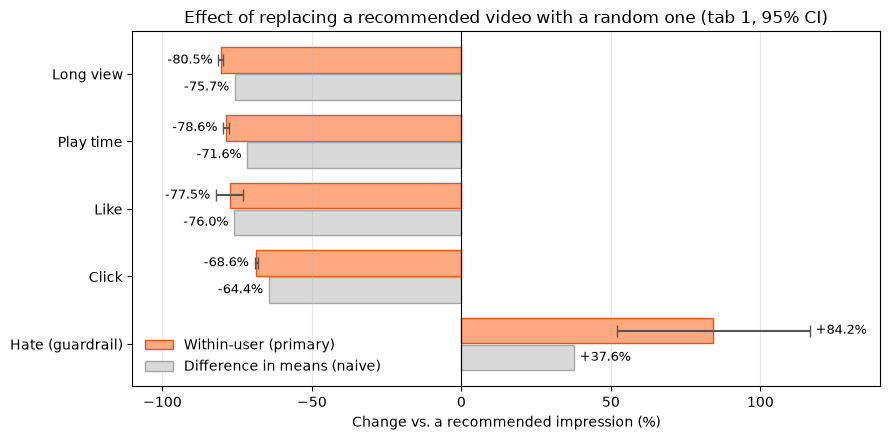

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import os

names = {'long_view': 'Long view', 'play_sec': 'Play time', 'is_like': 'Like',
         'is_click': 'Click', 'is_hate': 'Hate (guardrail)'}
plot_df = results.loc[list(names)]                                     # fixed display order
fe_ci = 100 * 1.96 * plot_df['fe_se'] / plot_df['ctrl_mean']            # 95% CI half-width in %

y = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y - 0.2, plot_df['fe_lift_pct'], height=0.38, xerr=fe_ci, capsize=4,
        color='#FFA980', edgecolor='#E0561A', ecolor='#555555', label='Within-user (primary)')
ax.barh(y + 0.2, plot_df['dm_lift_pct'], height=0.38,
        color='#D9D9D9', edgecolor='#A6A6A6', label='Difference in means (naive)')

# value labels just past the end of each bar (and past the CI for within-user bars)
for yi, fe, dm, ci in zip(y, plot_df['fe_lift_pct'], plot_df['dm_lift_pct'], fe_ci):
    for val, offset, pos in [(fe, ci, yi - 0.2), (dm, 0, yi + 0.2)]:
        x = val + np.sign(val) * (offset + 2)
        ax.text(x, pos, f'{val:+.1f}%', va='center', ha='left' if val > 0 else 'right', fontsize=9)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(y, [names[m] for m in plot_df.index])
ax.invert_yaxis()
ax.set_xlim(-110, 140)
ax.set_xlabel('Change vs. a recommended impression (%)')
ax.set_title('Effect of replacing a recommended video with a random one (tab 1, 95% CI)')
ax.legend(loc='lower left', frameon=False)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/main_effect.png', dpi=150, bbox_inches='tight')
plt.show()

**Key findings: treatment effect**
- 27,024 users in tab 1; 90.7% appear in both groups, so the within-user estimator draws on most of the sample. 95.4% of impressions have pre-period data.
- Random exposure lowers every positive metric under all three estimators (all |t| > 30). Within-user estimates: long view −80.5% (−0.283 on a 0.352 base), play time −19.3s (−78.6%), click −68.6%, like −77.5%.
- Hate rate rises by +0.00069 (+84%, t ≈ 4.9) within user; the difference-in-means estimate (+38%, t ≈ 2.2) is much weaker.
- **Difference in means understates the cost.** Within-user estimates are larger in magnitude for every metric, and CUPED shifts the estimates in the same direction, indicating that treatment and control impressions come from different user mixes. The within-user estimate is the primary result.
- **Difference in means understates the cost.** Treatment impressions come from users with higher pre-period engagement (e.g. play time +13.2%), so the naive comparison is biased toward zero. Within-user estimates are larger in magnitude for every metric, and CUPED's shift matches the direction of the pre-period imbalance metric by metric. The within-user estimate is the primary result.